# Module 4 Homework (2026 Cohort) — Trading Simulations

Stock Markets Analytics Zoomcamp · Module 4 · Author: Adrian Maulana Muhammad

This notebook reproduces the pipeline of `[2026]_Module_04_Colab_Trading_Simulations.ipynb` (same features, same split,
same hard-coded best models, same `$100 per positive prediction` simulation) and applies the changes requested by each question
on a **fresh** pipeline run. Hyper-parameter tuning and the DNN section are skipped, as in the original notebook, because they
don't feed any prediction used in the simulation.

| Question | Answer |
|---|---|
| Q1 — CAGR of `pred10_rf_best_rule_55` with fewer dummies | **1.1359** |
| Q2 — threshold of the second-best RF rule with < 5 trades/day | **0.56** |
| Q3 — number of trades of `pred5_clf_10` with target `growth_future_30d > 1.022` | **7337** |
| Q4 — ideal strategy | see the last section |

## 0. Setup

In [7]:
import os

DATA_PATH = "stocks_df_combined_2026_09_18.parquet.brotli"

if not os.path.exists(DATA_PATH):
    !pip install -q gdown
    !gdown 1oQSUMCs2DyQQIh8Y62UhrT00cIsE9Sr5 -O {DATA_PATH}

print(DATA_PATH, "found:", os.path.exists(DATA_PATH))

stocks_df_combined_2026_09_18.parquet.brotli found: True


In [8]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

pd.options.mode.chained_assignment = None
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

df_full_raw = pd.read_parquet(DATA_PATH)
df_full_raw.shape

(240759, 203)

### Pipeline helpers
The functions below are the notebook cells wrapped into functions so each question can start from a clean state.
Two switches cover the homework changes:
- `short_dummies=True` → **Q1/Q2**: remove `Ticker` and `month_wom` from `CATEGORICAL` right before `pd.get_dummies()`
- `target_threshold=1.022` → **Q3**: `is_positive_growth_30d_future = growth_future_30d > 1.022`

In [9]:
TECHNICAL_INDICATORS = ['adx', 'adxr', 'apo', 'aroon_1','aroon_2', 'aroonosc', 'bop', 'cci', 'cmo','dx', 'macd', 'macdsignal', 'macdhist', 'macd_ext',
 'macdsignal_ext', 'macdhist_ext', 'macd_fix', 'macdsignal_fix', 'macdhist_fix', 'mfi', 'minus_di', 'mom', 'plus_di', 'dm', 'ppo',
 'roc', 'rocp', 'rocr', 'rocr100', 'rsi', 'slowk', 'slowd', 'fastk', 'fastd', 'fastk_rsi', 'fastd_rsi', 'trix', 'ultosc', 'willr',
 'ad', 'adosc', 'obv', 'atr', 'natr', 'ht_dcperiod', 'ht_dcphase', 'ht_phasor_inphase', 'ht_phasor_quadrature', 'ht_sine_sine', 'ht_sine_leadsine',
 'ht_trendmod', 'avgprice', 'medprice', 'typprice', 'wclprice']
MACRO = ['gdppot_us_yoy', 'gdppot_us_qoq', 'cpi_core_yoy', 'cpi_core_mom', 'FEDFUNDS', 'DGS1', 'DGS5', 'DGS10']
CUSTOM_NUMERICAL = ['SMA10', 'SMA20', 'growing_moving_average', 'high_minus_low_relative', 'volatility', 'ln_volume', 'div_payout', 'stock_split']


def temporal_split(df, min_date, max_date, train_prop=0.7, val_prop=0.15, test_prop=0.15):
    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_prop)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_prop)
    df['split'] = np.where(df['Date'] <= train_end, 'train', np.where(df['Date'] <= val_end, 'validation', 'test'))
    return df


def prepare_data(short_dummies=False, target_threshold=None):
    df_full = df_full_raw.copy()
    if target_threshold is not None:  # Q3
        df_full['is_positive_growth_30d_future'] = (df_full['growth_future_30d'] > target_threshold).astype(int)

    GROWTH = [g for g in df_full.keys() if (g.find('growth_') == 0) & (g.find('future') < 0)]
    TECHNICAL_PATTERNS = [g for g in df_full.keys() if g.find('cdl') >= 0]
    df_full['ln_volume'] = df_full.Volume.apply(lambda x: np.log(x + 1e-6))
    df_full['div_payout'] = (df_full.Dividends > 0).astype(int)
    df_full['stock_split'] = (df_full['Stock Splits'] > 0).astype(int)
    NUMERICAL = GROWTH + TECHNICAL_INDICATORS + TECHNICAL_PATTERNS + CUSTOM_NUMERICAL + MACRO

    df = df_full[df_full.Date >= '2000-01-01'].copy()
    df['Month'] = pd.to_datetime(df['Month'], format='%m').dt.strftime('%B')
    df['Weekday'] = df['Weekday'].astype('string')
    wom = df.Date.apply(lambda d: (d.day - 1) // 7 + 1).astype(str)
    df['month_wom'] = df.Month + '_w' + wom

    CATEGORICAL = ['Month', 'Weekday', 'Ticker', 'ticker_type', 'month_wom']
    if short_dummies:  # Q1: fewer dummy variables
        CATEGORICAL = [c for c in CATEGORICAL if c not in ('Ticker', 'month_wom')]

    dummy_variables = pd.get_dummies(df[CATEGORICAL], dtype='int32')
    DUMMIES = dummy_variables.keys().to_list()
    df_with_dummies = pd.concat([df, dummy_variables], axis=1)
    df_with_dummies = temporal_split(df_with_dummies, df_with_dummies.Date.min(), df_with_dummies.Date.max())
    print('CATEGORICAL used for dummies:', CATEGORICAL)
    return df_with_dummies.copy(), NUMERICAL, DUMMIES


def clean(df):
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)
    return df


def train_and_predict(new_df, features_list, to_predict='is_positive_growth_30d_future'):
    """Manual rules pred0-4, Decision Trees pred5-9, Random Forest pred10-11 (as in the notebook)."""
    new_df['pred0_manual_cci'] = (new_df.cci > 200).astype(int)
    new_df['pred1_manual_prev_g1'] = (new_df.growth_30d > 1).astype(int)
    new_df['pred2_manual_prev_g1_and_snp'] = ((new_df['growth_30d'] > 1) & (new_df['growth_snp500_30d'] > 1)).astype(int)
    new_df['pred3_manual_dgs10_5'] = ((new_df['DGS10'] <= 4.5) & (new_df['DGS5'] <= 4)).astype(int)
    new_df['pred4_manual_dgs10_fedfunds'] = ((new_df['DGS10'] > 4) & (new_df['FEDFUNDS'] <= 4.795)).astype(int)

    tv = new_df[new_df.split.isin(['train', 'validation'])]
    X_train_valid = clean(tv[features_list].copy()); y_train_valid = tv[to_predict]
    te = new_df[new_df.split == 'test']
    X_test = clean(te[features_list].copy()); y_test = te[to_predict]
    X_all = clean(new_df[features_list].copy())

    m = {}
    for depth, col in [(10, 'pred5_clf_10'), (4, 'pred6_clf_4'), (7, 'pred7_clf_second_best')]:
        clf = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train_valid, y_train_valid)
        new_df[col] = clf.predict(X_all)
        m[depth] = clf
    clf_best = m[7]
    rf_best = RandomForestClassifier(n_estimators=100, max_depth=13, random_state=42, n_jobs=-1).fit(X_train_valid, y_train_valid)

    p = clf_best.predict_proba(X_all)[:, 1]
    new_df['proba_pred8'] = p; new_df['pred8_clf_second_best_rule_56'] = (p >= 0.56).astype(int)
    new_df['proba_pred9'] = p; new_df['pred9_clf_second_best_rule_66'] = (p >= 0.66).astype(int)
    p = rf_best.predict_proba(X_all)[:, 1]
    new_df['proba_pred10'] = p; new_df['pred10_rf_best_rule_55'] = (p >= 0.55).astype(int)
    new_df['proba_pred11'] = p; new_df['pred11_rf_best_rule_65'] = (p >= 0.65).astype(int)
    return dict(clf_best=clf_best, rf_best=rf_best, X_test=X_test, y_test=y_test, rf_proba_all=p)


def simulate(new_df):
    """Simulation 1: invest $100 in every positive prediction on TEST, hold 30 days, 0.2% fees (as in the notebook)."""
    PREDICTIONS = [k for k in new_df.keys() if k.startswith('pred')]
    rows = []
    for pred in PREDICTIONS:
        sub = new_df[(new_df.split == 'test') & (new_df[pred] == 1)]
        n = len(sub)
        gross = (100 * (sub['growth_future_30d'] - 1)).sum()
        fees = -100 * 0.002 * n
        net = gross + fees
        daily = sub.groupby('Date')[pred].count()
        avg_day = daily.mean() if n else np.nan
        capital = 100 * 30 * daily.quantile(0.75) if n else np.nan
        cagr = ((capital + net) / capital) ** (1 / 4) if n else np.nan
        rows.append((pred, n, gross, fees, net, (-fees / gross if gross > 0 else None),
                     (net / n if n else None), avg_day, capital, cagr))
    cols = ['prediction', 'sim1_count_investments', 'sim1_gross_rev', 'sim1_fees', 'sim1_net_rev', 'sim1_fees_percentage',
            'sim1_average_net_revenue', 'sim1_avg_investments_per_day', 'sim1_capital', 'sim1_CAGR']
    res = pd.DataFrame(rows, columns=cols)
    res['sim1_growth_capital_4y'] = (res.sim1_net_rev + res.sim1_capital) / res.sim1_capital
    return res


def tpr_fpr_dataframe(y_true, y_pred, only_even=False):
    scores = []
    thresholds = np.linspace(0, 1, 51) if only_even else np.linspace(0, 1, 101)
    precision = recall = f1_score = 0
    for t in thresholds:
        pp, pn = (y_pred >= t), (y_pred < t)
        tp = (pp & (y_true == 1)).sum(); tn = (pn & (y_true == 0)).sum()
        fp = (pp & (y_true == 0)).sum(); fn = (pn & (y_true == 1)).sum()
        if tp + fp > 0: precision = tp / (tp + fp)
        if tp + fn > 0: recall = tp / (tp + fn)
        if precision + recall > 0: f1_score = 2 * precision * recall / (precision + recall)
        scores.append((t, tp, fp, fn, tn, precision, recall, (tp + tn) / (tp + tn + fp + fn), f1_score))
    d = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall', 'accuracy', 'f1_score'])
    d['tpr'] = d.tp / (d.tp + d.fn); d['fpr'] = d.fp / (d.fp + d.tn)
    return d

## Question 1: Less Features is More
Remove `Ticker` and `month_wom` from `CATEGORICAL` just before `pd.get_dummies()`. Expected: 301 → 208 features,
and the CAGR of `pred10_rf_best_rule_55` slightly above the original 1.1195.

In [10]:
%%time
new_df, NUMERICAL, DUMMIES = prepare_data(short_dummies=True)
print(f"df_with_dummies[NUMERICAL+DUMMIES] -> {len(NUMERICAL + DUMMIES)} features ({len(DUMMIES)} dummies)")
models = train_and_predict(new_df, NUMERICAL + DUMMIES)
df_sim1_results = simulate(new_df)
df_sim1_results.round(4)

CATEGORICAL used for dummies: ['Month', 'Weekday', 'ticker_type']
df_with_dummies[NUMERICAL+DUMMIES] -> 208 features (22 dummies)
CPU times: user 5min 5s, sys: 5.43 s, total: 5min 10s
Wall time: 3min 34s


,prediction,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_fees_percentage,sim1_average_net_revenue,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR,sim1_growth_capital_4y
0,pred0_manual_cci,921,1839.3929,-184.2,1655.1929,0.1001,1.7972,1.8758,6000.0,1.0628,1.2759
1,pred1_manual_prev_g1,19158,44647.3669,-3831.6,40815.7669,0.0858,2.1305,18.4212,72000.0,1.1188,1.5669
2,pred2_manual_prev_g1_and_snp,15244,33808.0942,-3048.8,30759.2942,0.0902,2.0178,21.7151,75000.0,1.0897,1.4101
3,pred3_manual_dgs10_5,15910,40723.8030,-3182.0,37541.8030,0.0781,2.3596,31.9478,99000.0,1.0837,1.3792
4,pred4_manual_dgs10_fedfunds,15921,18532.8800,-3184.2,15348.6800,0.1718,0.9641,31.9058,99000.0,1.0367,1.1550
5,pred5_clf_10,9699,31330.7732,-1939.8,29390.9732,0.0619,3.0303,10.5884,51000.0,1.1205,1.5763
6,pred6_clf_4,6677,22383.4460,-1335.4,21048.0460,0.0597,3.1523,30.3500,99000.0,1.0494,1.2126
7,pred7_clf_second_best,5833,21481.0577,-1166.6,20314.4577,0.0543,3.4827,14.1922,87000.0,1.0539,1.2335
8,pred8_clf_second_best_rule_56,5820,21461.1552,-1164.0,20297.1552,0.0542,3.4875,14.1951,87000.0,1.0538,1.2333
9,pred9_clf_second_best_rule_66,4134,11485.3102,-826.8,10658.5102,0.0720,2.5783,11.1429,75000.0,1.0338,1.1421


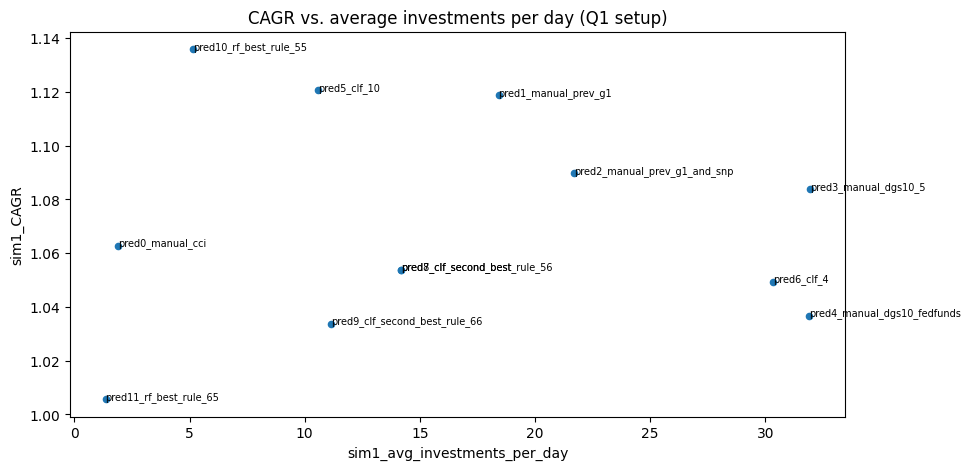

In [11]:
ax = df_sim1_results.dropna().plot.scatter(x='sim1_avg_investments_per_day', y='sim1_CAGR', figsize=(10, 5),
                                          title='CAGR vs. average investments per day (Q1 setup)')
for _, r in df_sim1_results.dropna().iterrows():
    ax.annotate(r.prediction, (r.sim1_avg_investments_per_day, r.sim1_CAGR), fontsize=7)
plt.show()

In [12]:
q1 = df_sim1_results.set_index('prediction').loc['pred10_rf_best_rule_55']
print(f"Q1 ANSWER: CAGR of pred10_rf_best_rule_55 = {q1.sim1_CAGR:.4f} (original setup: 1.1195)")

Q1 ANSWER: CAGR of pred10_rf_best_rule_55 = 1.1359 (original setup: 1.1195)


## Question 2: Most Efficient Random Forest Decision Rule
Same Q1 setup (RF `max_depth=13`, `n_estimators=100`). First the `tpr_fpr_dataframe` for the Random Forest
(`y_pred_test = rf_best.predict_proba(X_test)` instead of `clf_best`), then new rules for thresholds 0.56 … 0.64.

*Note:* in the original notebook the Logistic Regression section scales `X_test` in place before this cell; here the RF is
scored on the unscaled `X_test` it was trained on, which is what the table is meant to show.

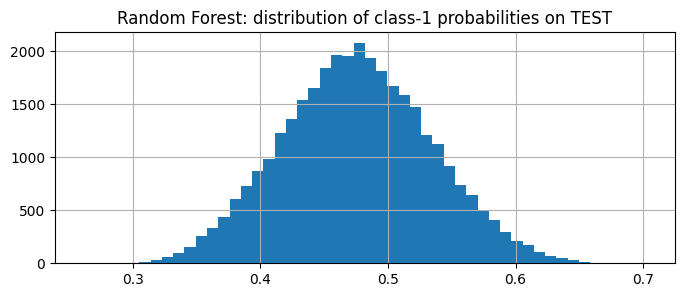

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr,total_trades
50,0.50,6668,4455,12238,9802,0.5995,0.3527,0.4966,0.4441,0.3527,0.3125,11123
51,0.51,5570,3660,13336,10597,0.6035,0.2946,0.4875,0.3959,0.2946,0.2567,9230
52,0.52,4536,2930,14370,11327,0.6076,0.2399,0.4783,0.3440,0.2399,0.2055,7466
53,0.53,3607,2317,15299,11940,0.6089,0.1908,0.4688,0.2905,0.1908,0.1625,5924
54,0.54,2836,1803,16070,12454,0.6113,0.1500,0.4611,0.2409,0.1500,0.1265,4639
55,0.55,2168,1346,16738,12911,0.6170,0.1147,0.4547,0.1934,0.1147,0.0944,3514
56,0.56,1607,1034,17299,13223,0.6085,0.0850,0.4472,0.1492,0.0850,0.0725,2641
57,0.57,1146,743,17760,13514,0.6067,0.0606,0.4421,0.1102,0.0606,0.0521,1889
58,0.58,805,525,18101,13732,0.6053,0.0426,0.4383,0.0796,0.0426,0.0368,1330
59,0.59,538,361,18368,13896,0.5984,0.0285,0.4352,0.0543,0.0285,0.0253,899


In [13]:
y_pred_test_class1 = models['rf_best'].predict_proba(models['X_test'])[:, 1]
pd.Series(y_pred_test_class1).hist(bins=50, figsize=(8, 3))
plt.title('Random Forest: distribution of class-1 probabilities on TEST'); plt.show()

df_scores = tpr_fpr_dataframe(models['y_test'].values, y_pred_test_class1)
df_scores['total_trades'] = df_scores.tp + df_scores.fp
df_scores[(df_scores.threshold >= 0.50) & (df_scores.threshold <= 0.70)].round(4)

In [14]:
# new predictors pred12 ... pred20 for thresholds 0.56 ... 0.64
y_pred_all_class1_array = models['rf_proba_all']
for k, thr in enumerate(range(56, 65), start=12):
    new_df[f'pred{k}_rf_best_rule_{thr}'] = (y_pred_all_class1_array >= thr / 100).astype(int)

df_sim1_results = simulate(new_df)
rf_rules = df_sim1_results[df_sim1_results.prediction.str.contains('rf_best_rule')].copy()
rf_rules['threshold'] = rf_rules.prediction.str.split('_').str[-1].astype(int) / 100
rf_rules = rf_rules.sort_values('threshold')
rf_rules[['prediction', 'threshold', 'sim1_count_investments', 'sim1_avg_investments_per_day', 'sim1_capital', 'sim1_CAGR']].round(4)

,prediction,threshold,sim1_count_investments,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR
10,pred10_rf_best_rule_55,0.55,3514,5.1601,18000.0,1.1359
12,pred12_rf_best_rule_56,0.56,2641,4.4017,15000.0,1.1177
13,pred13_rf_best_rule_57,0.57,1889,3.8085,15000.0,1.0912
14,pred14_rf_best_rule_58,0.58,1330,3.4635,15000.0,1.0665
15,pred15_rf_best_rule_59,0.59,899,3.0788,12000.0,1.0613
16,pred16_rf_best_rule_60,0.60,583,2.7762,12000.0,1.0442
17,pred17_rf_best_rule_61,0.61,352,2.5143,9750.0,1.0402
18,pred18_rf_best_rule_62,0.62,204,2.0816,9000.0,1.0259
19,pred19_rf_best_rule_63,0.63,123,1.6849,6000.0,1.0193
20,pred20_rf_best_rule_64,0.64,65,1.4444,6000.0,1.0089


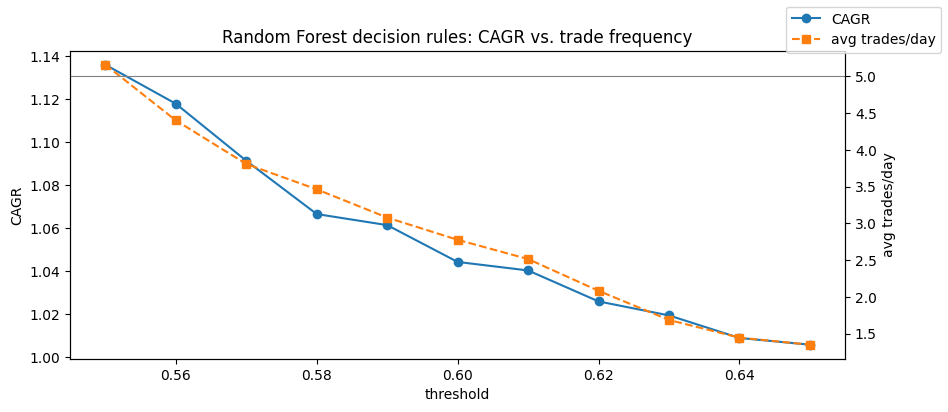

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(rf_rules.threshold, rf_rules.sim1_CAGR, 'o-', label='CAGR'); ax1.set_ylabel('CAGR'); ax1.set_xlabel('threshold')
ax2 = ax1.twinx(); ax2.plot(rf_rules.threshold, rf_rules.sim1_avg_investments_per_day, 's--', color='tab:orange', label='avg trades/day')
ax2.axhline(5, color='grey', lw=0.8); ax2.set_ylabel('avg trades/day')
fig.legend(loc='upper right'); plt.title('Random Forest decision rules: CAGR vs. trade frequency'); plt.show()

In [16]:
under5 = rf_rules[rf_rules.sim1_avg_investments_per_day < 5]
best_under5 = under5.loc[under5.sim1_CAGR.idxmax()]
print(f"Q2 ANSWER: threshold = {best_under5.threshold:.2f} ({best_under5.prediction}), "
      f"CAGR = {best_under5.sim1_CAGR:.4f}, avg trades/day = {best_under5.sim1_avg_investments_per_day:.2f}")

Q2 ANSWER: threshold = 0.56 (pred12_rf_best_rule_56), CAGR = 1.1177, avg trades/day = 4.40


Higher thresholds give fewer trades (TP+FP) and slightly higher precision, but CAGR does **not** increase:
0.55 stays the best overall (≈5.2 trades/day), while **0.56** is the best rule within the "< 5 trades/day" subspace.

In [17]:
del new_df, models, df_sim1_results, rf_rules; gc.collect();

## Question 3: Redefining the Growth Target
Fresh run of the **original** setup (all dummies), with `is_positive_growth_30d_future = 1 if growth_future_30d > 1.022`.

In [18]:
df_full_raw[['growth_future_30d', 'is_positive_growth_30d_future']].describe().round(4)

,growth_future_30d,is_positive_growth_30d_future
count,239769.0000,240759.0000
mean,1.0261,0.5920
std,0.1220,0.4915
min,0.2461,0.0000
25%,0.9607,0.0000
50%,1.0217,1.0000
75%,1.0856,1.0000
max,5.1797,1.0000


In [19]:
%%time
new_df, NUMERICAL, DUMMIES = prepare_data(short_dummies=False, target_threshold=1.022)
print(f"features: {len(NUMERICAL + DUMMIES)}; share of class 1 after redefinition: {new_df.is_positive_growth_30d_future.mean():.3f}")
models = train_and_predict(new_df, NUMERICAL + DUMMIES)
df_sim1_results = simulate(new_df)
df_sim1_results.sort_values('sim1_CAGR', ascending=False).round(4)

CATEGORICAL used for dummies: ['Month', 'Weekday', 'Ticker', 'ticker_type', 'month_wom']
features: 301; share of class 1 after redefinition: 0.491
CPU times: user 4min 41s, sys: 2.88 s, total: 4min 44s
Wall time: 3min 16s


,prediction,sim1_count_investments,sim1_gross_rev,sim1_fees,sim1_net_rev,sim1_fees_percentage,sim1_average_net_revenue,sim1_avg_investments_per_day,sim1_capital,sim1_CAGR,sim1_growth_capital_4y
5,pred5_clf_10,7337,18975.5556,-1467.4,17508.1556,0.0773,2.3863,8.0098,30000.0,1.1218,1.5836
1,pred1_manual_prev_g1,19158,44647.3669,-3831.6,40815.7669,0.0858,2.1305,18.4212,72000.0,1.1188,1.5669
2,pred2_manual_prev_g1_and_snp,15244,33808.0942,-3048.8,30759.2942,0.0902,2.0178,21.7151,75000.0,1.0897,1.4101
7,pred7_clf_second_best,10532,24570.0087,-2106.4,22463.6087,0.0857,2.1329,12.6739,57000.0,1.0866,1.3941
3,pred3_manual_dgs10_5,15910,40723.8030,-3182.0,37541.8030,0.0781,2.3596,31.9478,99000.0,1.0837,1.3792
8,pred8_clf_second_best_rule_56,10276,22124.8483,-2055.2,20069.6483,0.0929,1.9531,12.4860,54000.0,1.0822,1.3717
9,pred9_clf_second_best_rule_66,9746,19278.9596,-1949.2,17329.7596,0.1011,1.7781,13.4799,57000.0,1.0686,1.3040
0,pred0_manual_cci,921,1839.3929,-184.2,1655.1929,0.1001,1.7972,1.8758,6000.0,1.0628,1.2759
10,pred10_rf_best_rule_55,229,1691.8061,-45.8,1646.0061,0.0271,7.1878,2.2451,6000.0,1.0625,1.2743
6,pred6_clf_4,7209,24005.7549,-1441.8,22563.9549,0.0601,3.1300,30.8077,99000.0,1.0527,1.2279


In [20]:
best = df_sim1_results.loc[df_sim1_results.sim1_CAGR.idxmax()]
print(f"Best predictor by CAGR: {best.prediction} (CAGR {best.sim1_CAGR:.4f}, {best.sim1_avg_investments_per_day:.2f} trades/day)")
q3 = df_sim1_results.set_index('prediction').loc['pred5_clf_10']
print(f"Q3 ANSWER: number of trades for pred5_clf_10 = {int(q3.sim1_count_investments)}")

Best predictor by CAGR: pred5_clf_10 (CAGR 1.1218, 8.01 trades/day)
Q3 ANSWER: number of trades for pred5_clf_10 = 7337


## Question 4: [EXPLORATORY] My Ideal Trading Strategy

**Strategy: "Top-K high-confidence ensemble with volatility-scaled sizing"**

1. **Signal.** Each day, score every stock with the Random Forest probability (`proba_pred10`, short-dummy setup from Q1) and only consider candidates where the probability is ≥ the efficient threshold found in Q2 *and* the depth-7 Decision Tree also votes 1 (a simple 2-model agreement filter that removes noisy, low-conviction signals).
2. **Selection.** Rank the remaining candidates by probability and take at most the **top 3 per day** — this caps the daily trade count (time efficiency, fewer fees) while keeping the highest-precision bets.
3. **Sizing.** Instead of a flat $100, allocate a fixed daily budget (≈1/30 of capital, since each position is held 30 trading days) split across the selected names **inversely to their recent volatility**, with a hard cap of 10% of capital per ticker and 30% per `ticker_type` (sector/region) to avoid concentration.
4. **Risk management.** Skip new entries when the market regime is weak (e.g., S&P 500 30-day growth < 1 or VIX elevated), use a stop-loss around −8% and a take-profit around +15% within the 30-day holding window, and never let the same ticker exceed one open position at a time.
5. **Implementation / validation.** Implement it as a daily rebalancing loop on the TEST period that tracks cash and open positions explicitly (rather than the "$100 per signal" approximation), include the 0.2% round-trip fees, and compare CAGR, max drawdown, Sharpe ratio and average trades per day against `pred10_rf_best_rule_55`. Thresholds and K are tuned on the VALIDATION period only, to avoid look-ahead bias.
